In [11]:
import torch 
import numpy as np 
import matplotlib.pyplot as plt 
import sys
import os
import joblib

sys.path.insert(0, os.path.abspath("../../.."))
sys.path.insert(0, os.path.abspath("../.."))

from sklearn.decomposition import PCA 
from cartpole_wind import cartpole_model_factory, make_envs, sample_tasks_train
from utils.evaluation import run_meta_eval 

# Load the PCA model fitted in the original experiment
pca = joblib.load("../../../checkpoints/cartpole_wind_pca.joblib")

In [12]:
# Generate 20 new environments with randomly sampled wind 
new_env_configs = sample_tasks_train(num_envs=20)
new_envs = make_envs(new_env_configs)

for i, cfg in enumerate(new_env_configs):
    print(f"Environment {i}: Wind = {cfg['wind_mag']:.2f}")

Environment 0: Wind = -3.43
Environment 1: Wind = 3.44
Environment 2: Wind = -4.81
Environment 3: Wind = 4.24
Environment 4: Wind = -3.72
Environment 5: Wind = 4.07
Environment 6: Wind = -0.73
Environment 7: Wind = 0.49
Environment 8: Wind = -1.19
Environment 9: Wind = 2.76
Environment 10: Wind = -2.20
Environment 11: Wind = 4.59
Environment 12: Wind = 1.09
Environment 13: Wind = -0.06
Environment 14: Wind = 0.70
Environment 15: Wind = -1.77
Environment 16: Wind = -1.08
Environment 17: Wind = -3.26
Environment 18: Wind = -1.63
Environment 19: Wind = -1.16


In [13]:
# Create the RL2 model
model = cartpole_model_factory()

# Load the checkpoint
checkpoint_path = os.path.join("..", "..", "..", "checkpoints", "cartpole_wind.pt")
checkpoint = torch.load(checkpoint_path, map_location=torch.device("cpu"))

# Restore model weights
if isinstance(checkpoint, dict) and "model_state_dict" in checkpoint:
    model.load_state_dict(checkpoint["model_state_dict"])
else:
    model.load_state_dict(checkpoint)

In [14]:
new_num_envs = len(new_env_configs)
steps_per_env = 3000
model.eval()
new_obs, _ = new_envs.reset()
new_hidden_state = torch.zeros(1, new_num_envs, model.feat_extractor.h_dim)
new_prev_action = torch.zeros(new_num_envs, dtype=torch.long)
new_prev_reward = torch.zeros(new_num_envs, 1)
new_prev_done = torch.ones(new_num_envs, 1)

# Store hidden states separately for each new environment
new_env_hidden_accumulator = [[] for _ in range(new_num_envs)]

# Collect hidden states from the new environments
with torch.no_grad():
    for step in range(steps_per_env):
        logits, values, new_hidden_state = model(
            torch.tensor(new_obs).view(1, new_num_envs, -1).float(),
            new_prev_action.view(1, new_num_envs),
            new_prev_reward.view(1, new_num_envs, -1).float(),
            new_prev_done.view(1, new_num_envs, 1),
            new_hidden_state
        )

        current_h = new_hidden_state.squeeze(0).cpu().numpy()

        for i in range(new_num_envs):
            new_env_hidden_accumulator[i].append(current_h[i])

        actions = torch.argmax(logits, dim=-1)
        actions_env = actions.squeeze(0).cpu().numpy()

        new_obs, reward, terminated, truncated, info = new_envs.step(actions_env)

        new_prev_action = actions
        new_prev_reward = torch.tensor(reward).unsqueeze(1).float()

        # Update done flags for the next step
        done = np.logical_or(terminated, truncated)
        new_prev_done = torch.tensor(done, dtype=torch.float32).unsqueeze(1)

In [15]:
# Calculate the average GRU hidden state for each environment
new_avg_hidden_states = np.array([
    np.mean(h, axis=0) for h in new_env_hidden_accumulator
])

print(new_avg_hidden_states.shape)

(20, 64)


In [16]:
# Load the fitted K-Means model from the original experiment
kmeans = joblib.load("../../../checkpoints/cartpole_wind_kmeans.joblib")

# Assign the hidden states to the existing K Means clusters
new_cluster_labels = kmeans.predict(new_avg_hidden_states)

# Save the random wind magnitudes and their cluster assignments
new_wind_values = np.array([cfg["wind_mag"] for cfg in new_env_configs])

np.savez(
    "../../../checkpoints/cartpole_wind_random_results.npz",
    wind_values=new_wind_values,
    cluster_labels=new_cluster_labels
)

# Compare the assigned clusters with the actual wind
for i, cfg in enumerate(new_env_configs):
    print(
        f"Environment {i}: "
        f"Wind = {cfg['wind_mag']:.2f}, "
        f"Cluster = {new_cluster_labels[i]}"
    )

Environment 0: Wind = -3.43, Cluster = 1
Environment 1: Wind = 3.44, Cluster = 2
Environment 2: Wind = -4.81, Cluster = 1
Environment 3: Wind = 4.24, Cluster = 0
Environment 4: Wind = -3.72, Cluster = 1
Environment 5: Wind = 4.07, Cluster = 0
Environment 6: Wind = -0.73, Cluster = 1
Environment 7: Wind = 0.49, Cluster = 1
Environment 8: Wind = -1.19, Cluster = 1
Environment 9: Wind = 2.76, Cluster = 2
Environment 10: Wind = -2.20, Cluster = 1
Environment 11: Wind = 4.59, Cluster = 0
Environment 12: Wind = 1.09, Cluster = 1
Environment 13: Wind = -0.06, Cluster = 2
Environment 14: Wind = 0.70, Cluster = 1
Environment 15: Wind = -1.77, Cluster = 1
Environment 16: Wind = -1.08, Cluster = 1
Environment 17: Wind = -3.26, Cluster = 1
Environment 18: Wind = -1.63, Cluster = 1
Environment 19: Wind = -1.16, Cluster = 1


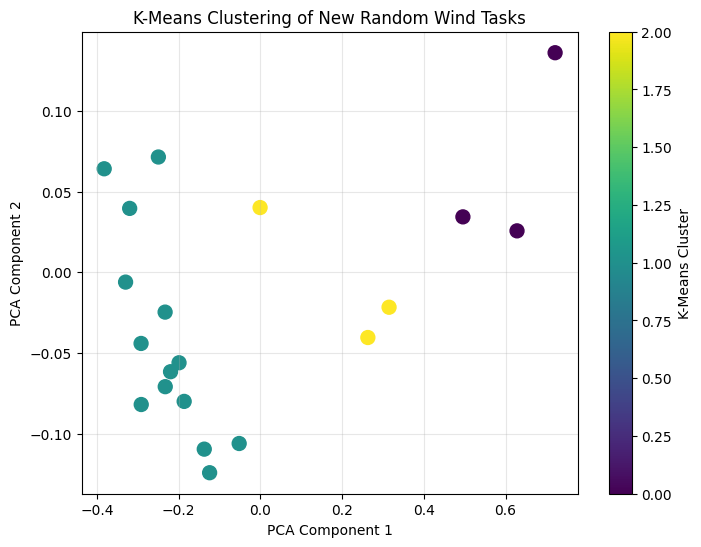

In [17]:
# Visualize the environments colored by their K Means clusters
new_reduced_h = pca.transform(new_avg_hidden_states)
plt.figure(figsize=(8, 6))

scatter = plt.scatter(
    new_reduced_h[:, 0],
    new_reduced_h[:, 1],
    c=new_cluster_labels,
    cmap="viridis",
    s=100
)

plt.colorbar(scatter, label="K-Means Cluster")
plt.title("K-Means Clustering of New Random Wind Tasks")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.grid(alpha=0.3)

plt.show()

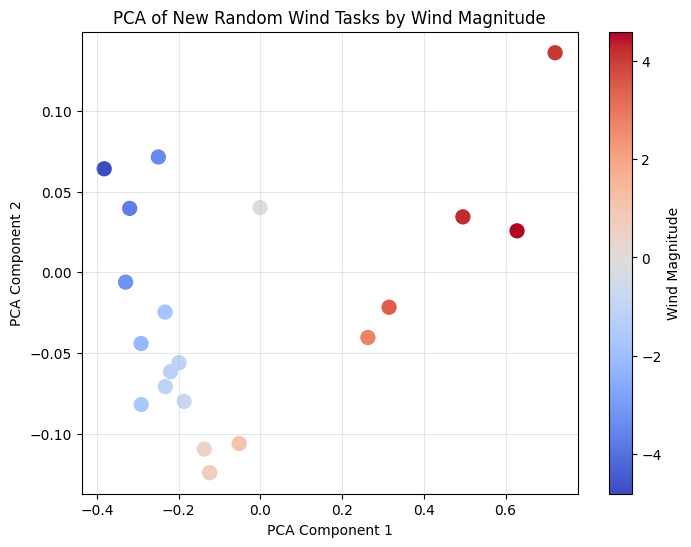

In [18]:
# Extract the wind  of the environment
new_wind_values = [cfg["wind_mag"] for cfg in new_env_configs]

# Visualize the hidden states colored by their wind
plt.figure(figsize=(8, 6))

scatter = plt.scatter(
    new_reduced_h[:, 0],
    new_reduced_h[:, 1],
    c=new_wind_values,
    cmap="coolwarm",
    s=100
)

plt.colorbar(scatter, label="Wind Magnitude")
plt.title("PCA of New Random Wind Tasks by Wind Magnitude")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.grid(alpha=0.3)

plt.show()